# 주사위 평균 시뮬레이션
공정한 6면체 주사위 n개(n = 1, 2, 5, 30)를 던져 눈의 평균을 10,000번 계산하고, 분포(히스토그램)와 통계값(Mean, SD)을 확인합니다.

In [1]:
# 라이브러리 불러오기 및 난수 시드 설정(재현성)
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

In [2]:
# 시뮬레이션 조건 설정
n_values = [1, 2, 5, 30]   # 주사위 개수
n_trials = 10_000          # 각 n값별 반복 횟수

In [3]:
# 시뮬레이션: n개 주사위를 던져 평균을 구하는 과정을 10,000번 반복하고 평균값을 모두 저장
results = {}
for n in n_values:
    rolls = rng.integers(1, 7, size=(n_trials, n))  # 1~6 균등 난수, (반복 x 주사위) 배열
    results[n] = rolls.mean(axis=1)                 # 반복마다 평균 계산 -> 길이 10,000

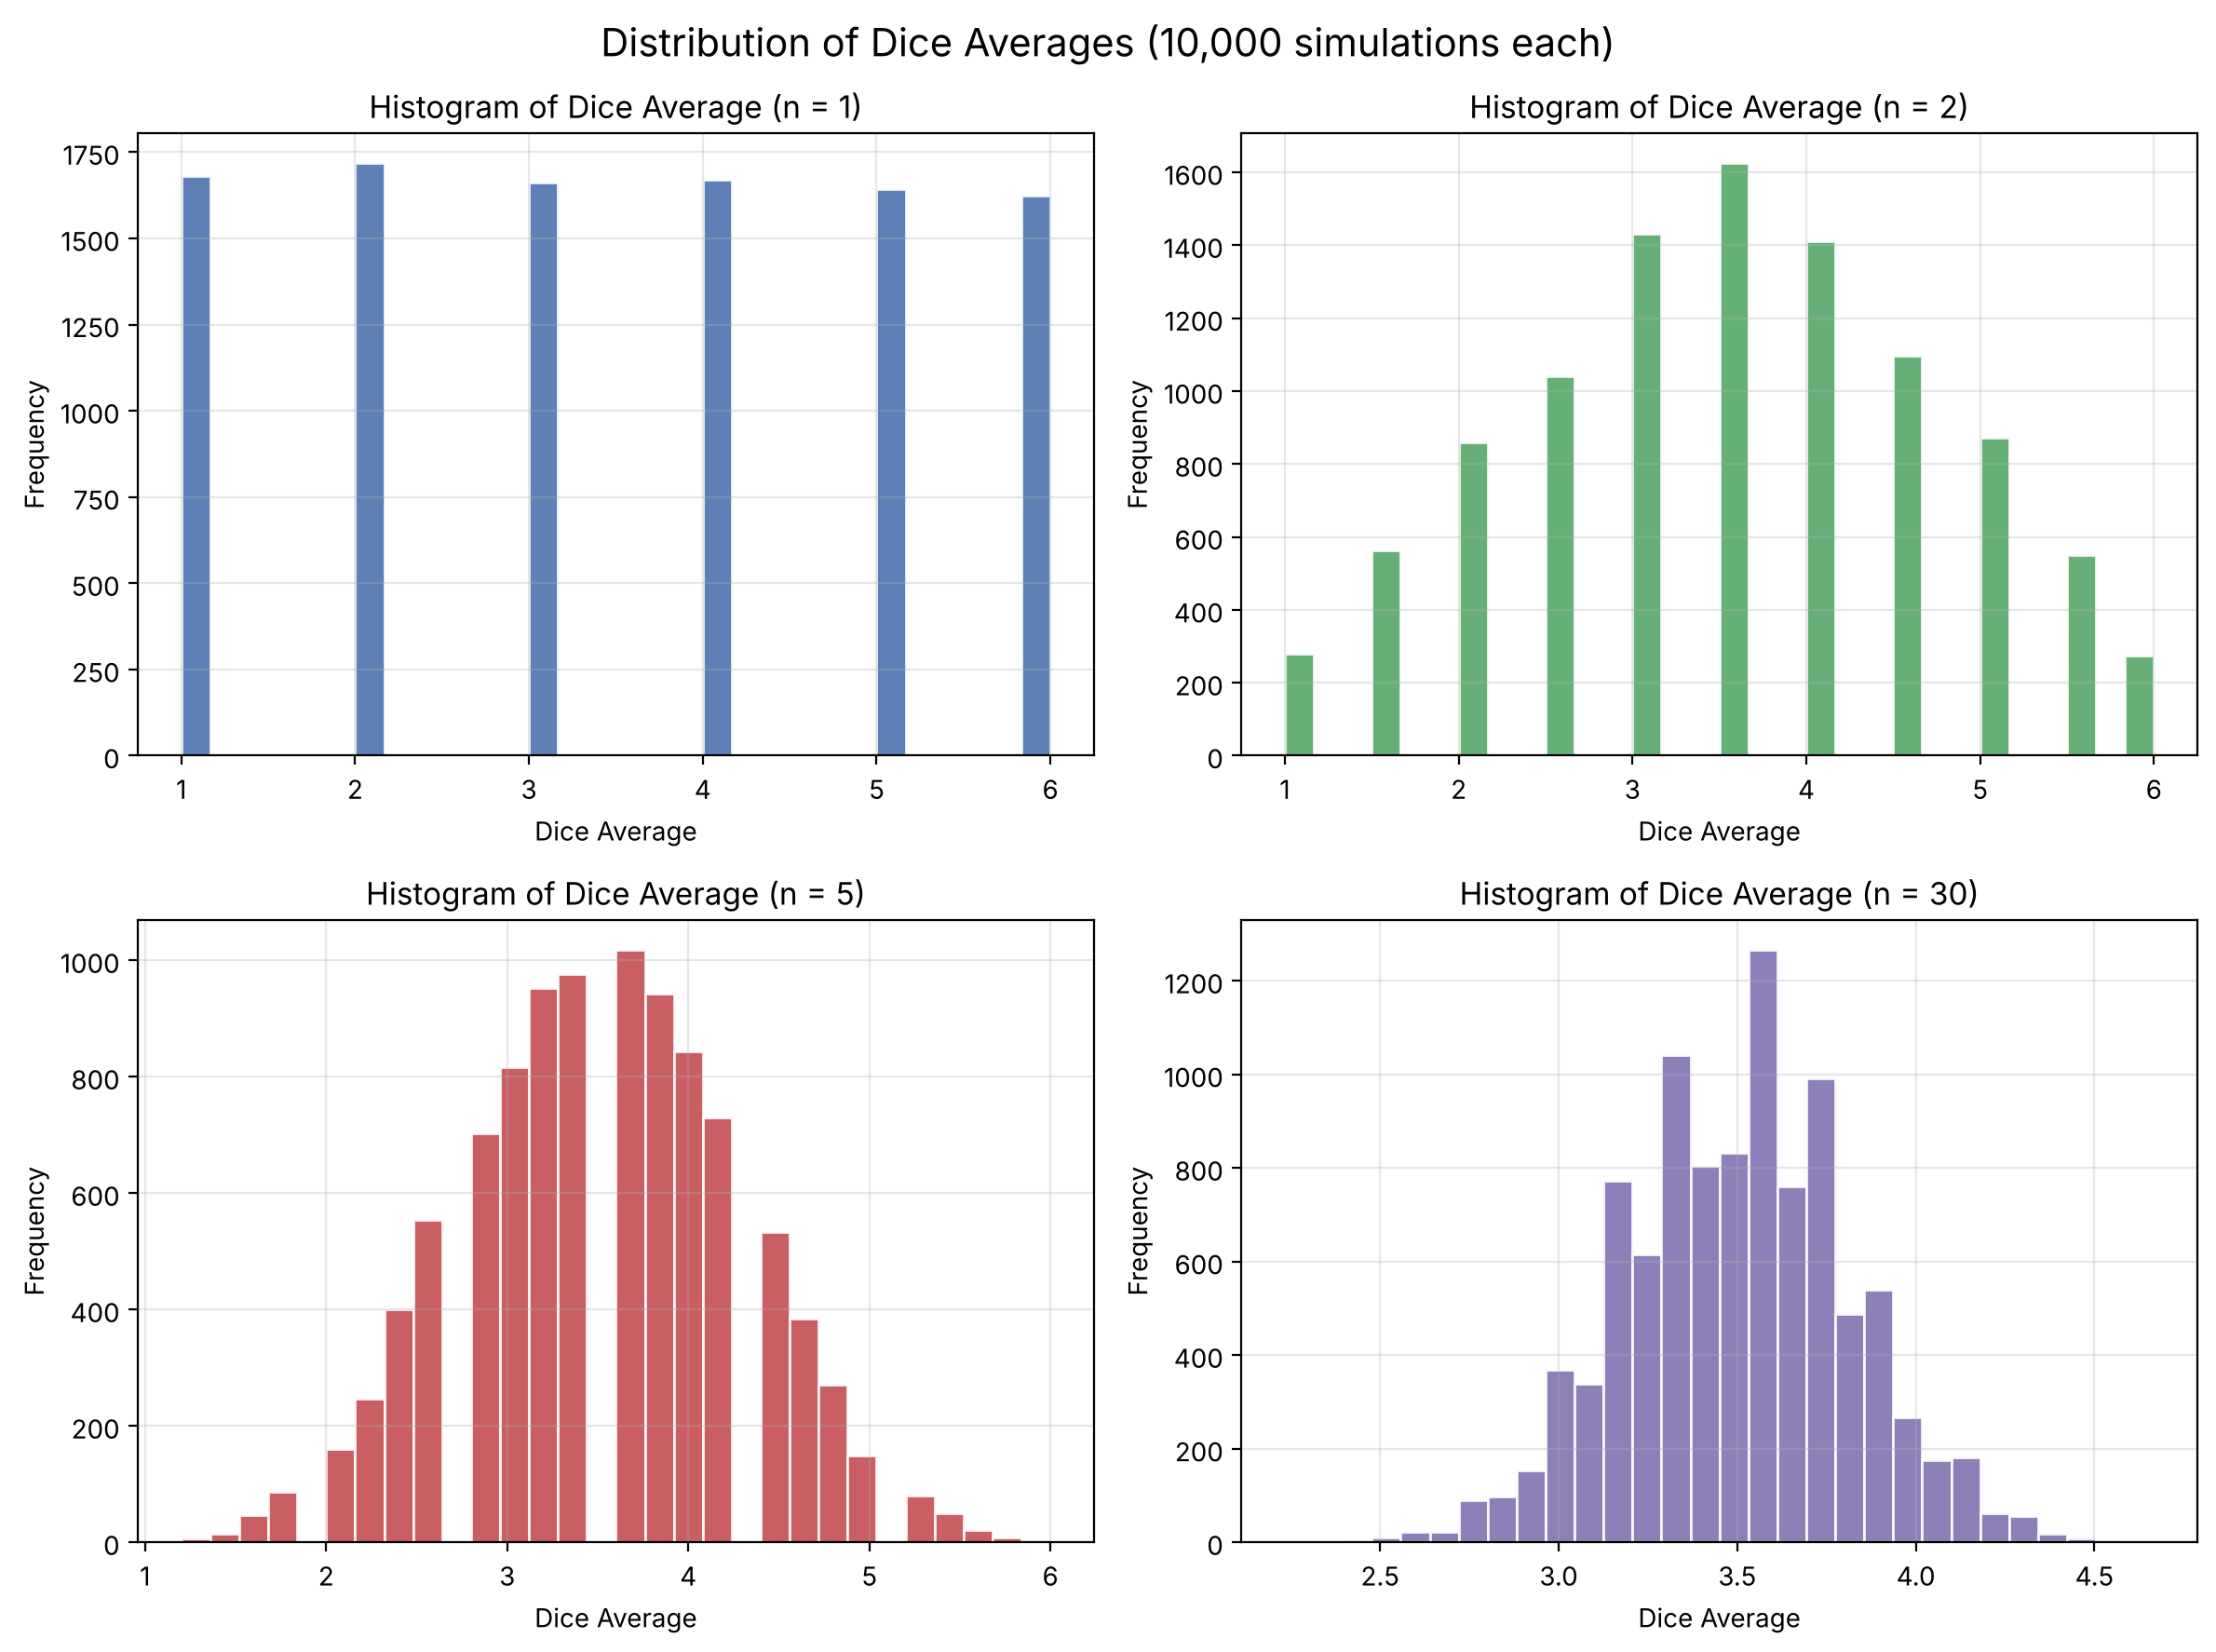

In [4]:
# 2x2 subplot 히스토그램 출력
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, n, c in zip(axes.ravel(), n_values, colors):
    ax.hist(results[n], bins=30, color=c, edgecolor="white", alpha=0.9)
    ax.set_title(f"Histogram of Dice Average (n = {n})")
    ax.set_xlabel("Dice Average")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)
fig.suptitle("Distribution of Dice Averages (10,000 simulations each)", fontsize=15)
plt.tight_layout()
plt.show()

In [5]:
# 통계값 출력: 평균값들의 Mean과 SD (n값별)
for n in n_values:
    avg = results[n]
    print(f"[n = {n:>2}]  simulations = {len(avg):,}")
    print(f"   Mean = {avg.mean():.4f}")
    print(f"   SD   = {avg.std():.4f}")
    print("-" * 36)

[n =  1]  simulations = 10,000
   Mean = 3.4752
   SD   = 1.7045
------------------------------------
[n =  2]  simulations = 10,000
   Mean = 3.5030
   SD   = 1.2100
------------------------------------
[n =  5]  simulations = 10,000
   Mean = 3.5030
   SD   = 0.7614
------------------------------------
[n = 30]  simulations = 10,000
   Mean = 3.4994
   SD   = 0.3156
------------------------------------


In [6]:
# 최종 확인: 4가지 경우 모두 10,000개의 평균값이 저장되었는지 검증
assert list(results) == [1, 2, 5, 30]
assert all(len(v) == 10_000 for v in results.values())
print("모든 n값에 대해 평균값 10,000개씩 정상 저장됨")

모든 n값에 대해 평균값 10,000개씩 정상 저장됨
